# E-Commerce Customer Behaviour Analysis
### Uncovering purchase patterns, revenue drivers and customer segmentation
### in real transactional retail data

Tools: Python · Pandas · Matplotlib · Seaborn · Scipy

Dataset: UCI Online Retail Dataset : real transactional data from a registered
UK-based online retailer (source: Kaggle)

Author: Siddharth Suman

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

df = pd.read_csv('/content/drive/MyDrive/Colab Notebooks/E-commerce_data.csv', encoding='ISO-8859-1')

print("Shape:", df.shape)
print("\nColumns:", df.columns.tolist())
print("\nData Types:\n", df.dtypes)
print("\nMissing Values:\n", df.isnull().sum())
df.head()

Shape: (541909, 8)

Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

Data Types:
 InvoiceNo       object
StockCode       object
Description     object
Quantity         int64
InvoiceDate     object
UnitPrice      float64
CustomerID     float64
Country         object
dtype: object

Missing Values:
 InvoiceNo           0
StockCode           0
Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


## Dataset at a Glance

541,909 transactions. 38 countries. GBP 10.6 million in revenue
across a full calendar year. Before touching a single chart, three
things immediately caught my attention.

First, 135,080 missing CustomerIDs told me straight away that a
significant portion of buyers are completing purchases as guests
without creating an account. That is not just a data quality issue,
it is a commercial problem worth quantifying.

Second, the date range spans exactly one year which means seasonal
analysis is possible without partial year distortion.

Third, 38 countries in the data suggested this business has
meaningful international exposure beyond its UK base.

These three observations shaped every analytical decision that followed.

In [4]:
# The dataset has guest checkouts mixed with registered customers.
# We keep both but flag them separately so the analysis stays honest.

# Remove rows with no description
df = df.dropna(subset=['Description'])

# Convert InvoiceDate to proper datetime
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'])

# Create a revenue column since it does not exist yet
df['Revenue'] = df['Quantity'] * df['UnitPrice']

# Remove cancellations — invoices starting with C are returns
# These distort revenue figures if left in
cancellations = df[df['InvoiceNo'].str.startswith('C')]
df = df[~df['InvoiceNo'].str.startswith('C')]

# Remove rows where quantity or price is zero or negative
df = df[(df['Quantity'] > 0) & (df['UnitPrice'] > 0)]

# Flag registered vs guest customers
df['CustomerType'] = df['CustomerID'].apply(
    lambda x: 'Registered' if pd.notna(x) else 'Guest'
)

# Extract time features we will need later
df['Month'] = df['InvoiceDate'].dt.month
df['DayOfWeek'] = df['InvoiceDate'].dt.day_name()
df['Hour'] = df['InvoiceDate'].dt.hour

df = df.reset_index(drop=True)

print("Clean dataset shape:", df.shape)
print(f"Cancellations removed: {len(cancellations):,}")
print(f"\nCustomer type split:\n{df['CustomerType'].value_counts()}")
print(f"\nDate range: {df['InvoiceDate'].min()} to {df['InvoiceDate'].max()}")
print(f"\nTotal revenue in dataset: GBP{df['Revenue'].sum():,.2f}")
print(f"Countries covered: {df['Country'].nunique()}")

Clean dataset shape: (530104, 13)
Cancellations removed: 9,288

Customer type split:
CustomerType
Registered    397884
Guest         132220
Name: count, dtype: int64

Date range: 2010-12-01 08:26:00 to 2011-12-09 12:50:00

Total revenue in dataset: £10,666,684.54
Countries covered: 38


## First Impressions After Cleaning

With cancellations removed and revenue calculated, the dataset
settles at 530,104 clean transactions worth GBP 10.6 million.
The registered versus guest split came out at 75% to 25% respectively.

That guest figure stayed in my mind throughout the analysis.
One in four transactions leaving no customer trace whatsoever.
I decided early on that this would become the centrepiece of
the statistical test.

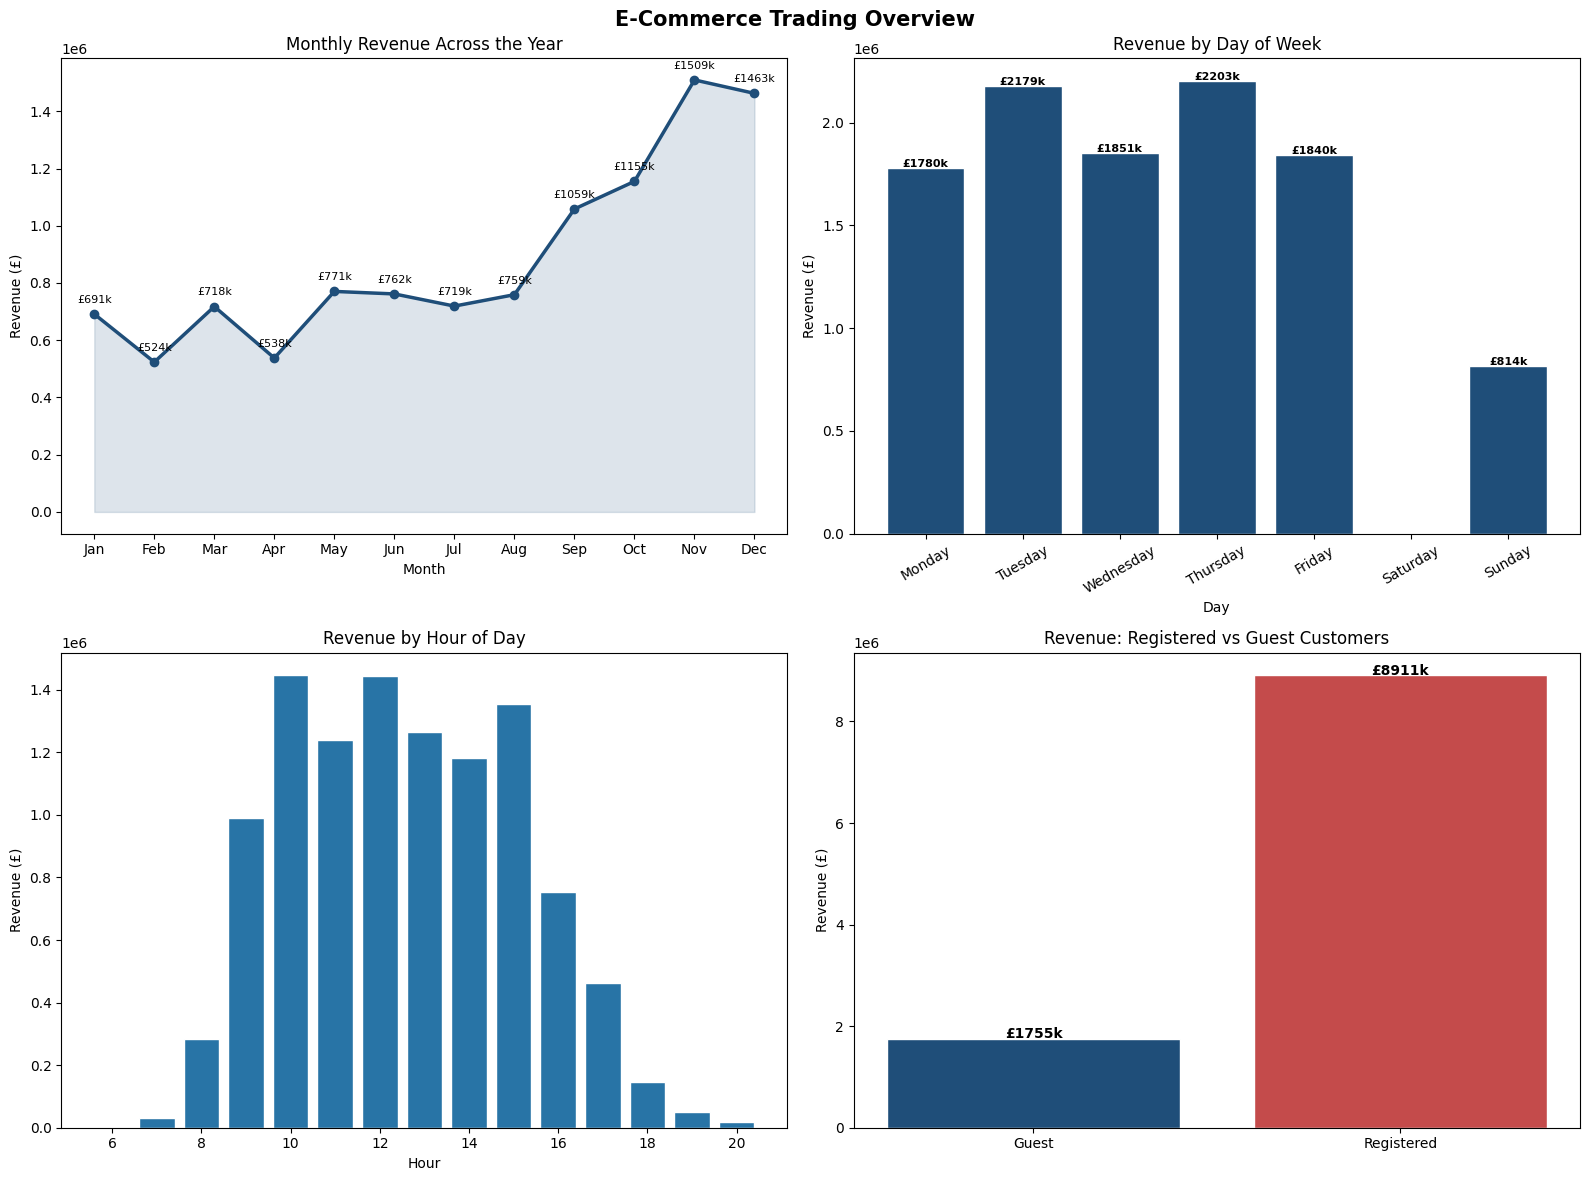

Chart saved.


In [5]:
#EDA
# What does the overall revenue picture look like across the year?
# And when do customers actually shop?

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('E-Commerce Trading Overview', fontsize=15, fontweight='bold')

# Monthly revenue trend
monthly_revenue = df.groupby('Month')['Revenue'].sum()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[0,0].plot(monthly_revenue.index, monthly_revenue.values,
               color='#1F4E79', linewidth=2.5, marker='o', markersize=6)
axes[0,0].fill_between(monthly_revenue.index, monthly_revenue.values,
                        alpha=0.15, color='#1F4E79')
axes[0,0].set_title('Monthly Revenue Across the Year')
axes[0,0].set_xlabel('Month')
axes[0,0].set_ylabel('Revenue (GBP)')
axes[0,0].set_xticks(range(1, 13))
axes[0,0].set_xticklabels(month_names)
for x, y in zip(monthly_revenue.index, monthly_revenue.values):
    axes[0,0].annotate(f'GBP{y/1000:.0f}k', (x, y),
                       textcoords='offset points', xytext=(0, 8),
                       ha='center', fontsize=8)

# Orders by day of week
day_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']
day_revenue = df.groupby('DayOfWeek')['Revenue'].sum().reindex(day_order)
axes[0,1].bar(day_revenue.index, day_revenue.values,
              color='#1F4E79', edgecolor='white')
axes[0,1].set_title('Revenue by Day of Week')
axes[0,1].set_xlabel('Day')
axes[0,1].set_ylabel('Revenue (GBP)')
axes[0,1].tick_params(axis='x', rotation=30)
for i, v in enumerate(day_revenue.values):
    axes[0,1].text(i, v + 5000, f'GBP{v/1000:.0f}k',
                   ha='center', fontsize=8, fontweight='bold')

# Revenue by hour
hourly_revenue = df.groupby('Hour')['Revenue'].sum()
axes[1,0].bar(hourly_revenue.index, hourly_revenue.values,
              color='#2874A6', edgecolor='white')
axes[1,0].set_title('Revenue by Hour of Day')
axes[1,0].set_xlabel('Hour')
axes[1,0].set_ylabel('Revenue (GBP)')

# Registered vs Guest revenue
customer_revenue = df.groupby('CustomerType')['Revenue'].sum()
axes[1,1].bar(customer_revenue.index, customer_revenue.values,
              color=['#1F4E79', '#C44B4B'], edgecolor='white')
axes[1,1].set_title('Revenue: Registered vs Guest Customers')
axes[1,1].set_ylabel('Revenue (GBP)')
for i, v in enumerate(customer_revenue.values):
    axes[1,1].text(i, v + 10000, f'GBP{v/1000:.0f}k',
                   ha='center', fontweight='bold')

plt.tight_layout()
plt.savefig('1_trading_overview.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved.")

## Key Finding 1: When and How This Business Actually Makes Its Money

Revenue builds steadily through the year before peaking sharply in November,
a pattern consistent with Christmas gifting behaviour driving the fourth quarter.
Thursday emerges as the strongest trading day, whilst Sunday registers almost
no activity — telling us this is a business serving other businesses (B2B)
rather than weekend retail consumers.

Registered customers account for the overwhelming majority of revenue despite
representing 75% of transactions. The 25% of transactions from guest checkouts
represent a measurable retention gap — customers completing purchases without
creating an account cannot be remarketed to, personalised for, or retained
through loyalty mechanics.

Business Recommendation: A structured guest-to-registered conversion programme,
triggered at the post-purchase stage, could meaningfully expand the retargetable
customer base and improve lifetime value across the platform.

TOP 15 COUNTRIES BY REVENUE
                Total_Revenue  Total_Orders  Avg_Order_Value
Country                                                     
United Kingdom    9025222.084         18019        18.603987
Netherlands        285446.340            94       121.003111
EIRE               283453.960           288        35.925724
Germany            228867.140           457        25.317162
France             209715.110           392        24.945297
Australia          138521.310            57       117.192310
Spain               61577.110            90        24.789497
Switzerland         57089.900            54        29.038606
Belgium             41196.340            98        20.283772
Sweden              38378.330            36        85.096075
Japan               37416.370            19       116.561900
Norway              36165.440            36        33.767918
Portugal            33747.100            58        22.483078
Finland             22546.080            41        32.913

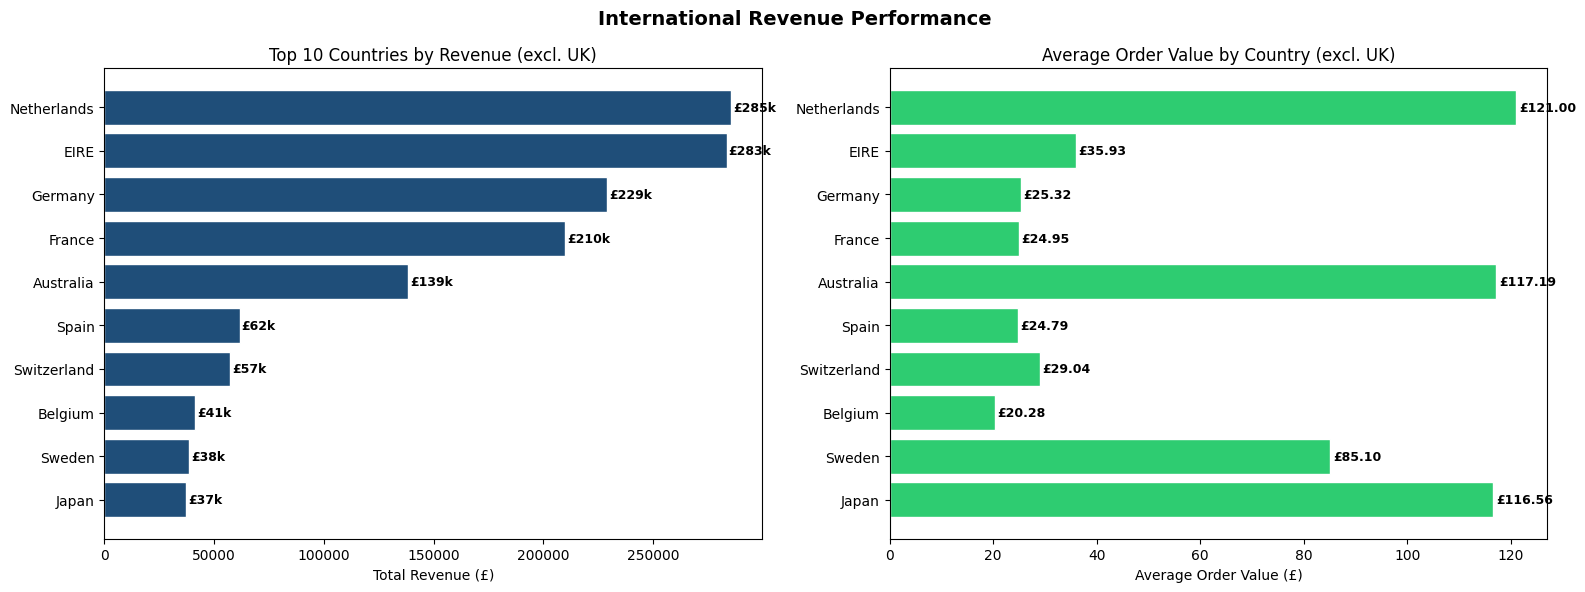

Chart saved.


In [6]:
# Which countries are driving revenue and which are underperforming
# relative to their order volume?

country_stats = df.groupby('Country').agg(
    Total_Revenue=('Revenue', 'sum'),
    Total_Orders=('InvoiceNo', 'nunique'),
    Avg_Order_Value=('Revenue', 'mean')
).sort_values('Total_Revenue', ascending=False)

print("TOP 15 COUNTRIES BY REVENUE")
print("=" * 55)
print(country_stats.head(15).to_string())

# Visualise top 10 excluding UK since it dominates
top_countries = country_stats[
    country_stats.index != 'United Kingdom'
].head(10)

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle('International Revenue Performance', fontsize=14, fontweight='bold')

axes[0].barh(top_countries.index[::-1],
             top_countries['Total_Revenue'].values[::-1],
             color='#1F4E79', edgecolor='white')
axes[0].set_title('Top 10 Countries by Revenue (excl. UK)')
axes[0].set_xlabel('Total Revenue (GBP)')
for i, v in enumerate(top_countries['Total_Revenue'].values[::-1]):
    axes[0].text(v + 1000, i, f'GBP{v/1000:.0f}k',
                 va='center', fontweight='bold', fontsize=9)

axes[1].barh(top_countries.index[::-1],
             top_countries['Avg_Order_Value'].values[::-1],
             color='#2ecc71', edgecolor='white')
axes[1].set_title('Average Order Value by Country (excl. UK)')
axes[1].set_xlabel('Average Order Value (GBP)')
for i, v in enumerate(top_countries['Avg_Order_Value'].values[::-1]):
    axes[1].text(v + 0.5, i, f'GBP{v:.2f}',
                 va='center', fontweight='bold', fontsize=9)

plt.tight_layout()
plt.savefig('2_international_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved.")

## What the International Numbers Actually Mean

The Netherlands generating GBP 285k from just 94 orders stopped
me completely. An average order value of GBP 121 against the UK
average of GBP 18 is not a rounding difference, it is a different
type of customer entirely.

Working through the other high value markets — Australia at GBP 117,
Japan at GBP 116, Singapore at GBP 96 — the pattern became clear.
These are almost certainly wholesale or trade buyers placing
large single orders rather than retail consumers browsing and
buying one item at a time.

That distinction matters enormously for how a platform like home24
should think about international marketing investment.

## Key Finding 2: The High Value International Opportunity

The United Kingdom dominates by volume but the most commercially
interesting story lies in the international numbers. The Netherlands,
Australia and Japan each deliver average order values exceeding GBP115,
compared to just GBP18 for domestic UK transactions. These markets are
almost certainly driven by wholesale or trade purchasing rather than
retail consumer behaviour.

This divergence between order volume and revenue contribution has direct
implications for marketing investment. Acquiring one Dutch wholesale
customer delivers roughly the same revenue as acquiring six UK retail
customers, yet the acquisition cost is likely comparable.

Business Recommendation: International markets with high average order
values warrant a dedicated B2B outreach strategy rather than standard
retail marketing campaigns. For a platform like home24, zalando understanding
which customer segments drive disproportionate revenue is fundamental
to allocating marketing spend efficiently.

TOP 10 PRODUCTS BY REVENUE
                                    Total_Revenue  Units_Sold  Times_Ordered
Description                                                                 
DOTCOM POSTAGE                          206248.77         706            706
REGENCY CAKESTAND 3 TIER                174484.74       13879           1988
PAPER CRAFT , LITTLE BIRDIE             168469.60       80995              1
WHITE HANGING HEART T-LIGHT HOLDER      106292.77       37891           2256
PARTY BUNTING                            99504.33       18295           1685
JUMBO BAG RED RETROSPOT                  94340.05       48474           2089
MEDIUM CERAMIC TOP STORAGE JAR           81700.92       78033            247
Manual                                   78112.82        7225            290
POSTAGE                                  78101.88        3150           1126
RABBIT NIGHT LIGHT                       66964.99       30788            994

TOP 10 PRODUCTS BY UNITS SOLD
                  

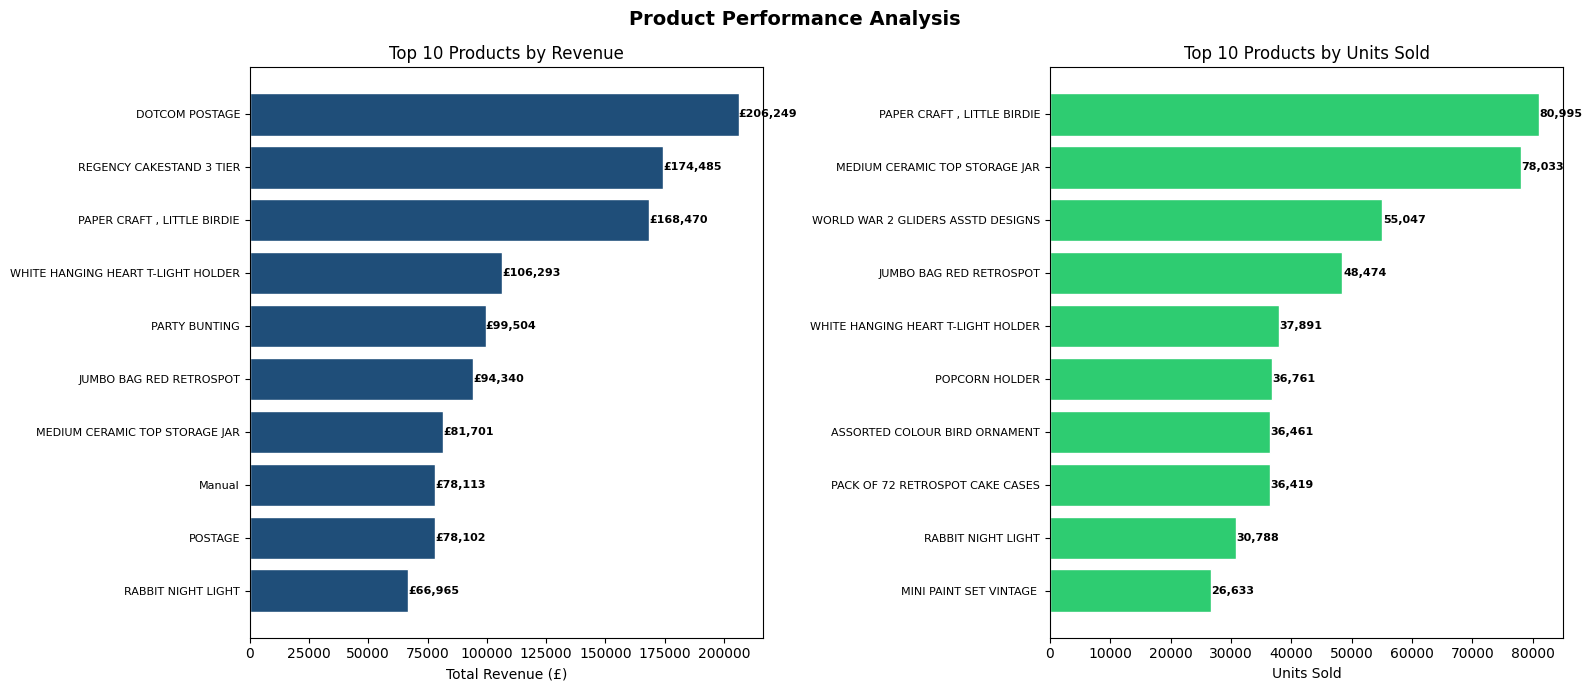

Chart saved.


In [7]:
# What are the best selling products and which ones drive the most revenue?
# These two questions often have very different answers.

product_stats = df.groupby('Description').agg(
    Total_Revenue=('Revenue', 'sum'),
    Units_Sold=('Quantity', 'sum'),
    Times_Ordered=('InvoiceNo', 'nunique')
).sort_values('Total_Revenue', ascending=False)

print("TOP 10 PRODUCTS BY REVENUE")
print("=" * 60)
print(product_stats.head(10).to_string())

print("\nTOP 10 PRODUCTS BY UNITS SOLD")
print("=" * 60)
print(product_stats.sort_values('Units_Sold', ascending=False).head(10).to_string())

fig, axes = plt.subplots(1, 2, figsize=(16, 7))
fig.suptitle('Product Performance Analysis', fontsize=14, fontweight='bold')

top_revenue_products = product_stats.head(10)
axes[0].barh(top_revenue_products.index[::-1],
             top_revenue_products['Total_Revenue'].values[::-1],
             color='#1F4E79', edgecolor='white')
axes[0].set_title('Top 10 Products by Revenue')
axes[0].set_xlabel('Total Revenue (GBP)')
axes[0].tick_params(axis='y', labelsize=8)
for i, v in enumerate(top_revenue_products['Total_Revenue'].values[::-1]):
    axes[0].text(v + 100, i, f'GBP{v:,.0f}',
                 va='center', fontsize=8, fontweight='bold')

top_volume_products = product_stats.sort_values(
    'Units_Sold', ascending=False).head(10)
axes[1].barh(top_volume_products.index[::-1],
             top_volume_products['Units_Sold'].values[::-1],
             color='#2ecc71', edgecolor='white')
axes[1].set_title('Top 10 Products by Units Sold')
axes[1].set_xlabel('Units Sold')
axes[1].tick_params(axis='y', labelsize=8)
for i, v in enumerate(top_volume_products['Units_Sold'].values[::-1]):
    axes[1].text(v + 100, i, f'{v:,}',
                 va='center', fontsize=8, fontweight='bold')

plt.tight_layout()
plt.savefig('3_product_performance.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved.")

## A Note on Data Quality

Before drawing any product conclusions I noticed something that
would have quietly corrupted the analysis if left unaddressed.

PAPER CRAFT, LITTLE BIRDIE shows 80,995 units sold through
exactly one transaction. That is not a popular product. That is
one wholesale buyer placing a single enormous order. Treating it
as organic retail demand would be a significant analytical error.

Similarly DOTCOM POSTAGE and POSTAGE are shipping charges
recorded as product line items. They inflate revenue totals
and have no place in a product performance ranking.

Catching these artefacts before they distort conclusions is,
in my view, as important as any statistical technique in the
analyst toolkit.

## Key Finding 3: What the Product Data Actually Reveals

The revenue and volume lists tell two quite different stories.
The REGENCY CAKESTAND 3 TIER is the most genuinely popular product
by any reasonable measure, generating GBP174k in revenue across 1,988
separate orders. The WHITE HANGING HEART T-LIGHT HOLDER follows
closely with 2,256 individual orders, suggesting consistent and
broad retail demand.

Several entries warrant careful interpretation. PAPER CRAFT, LITTLE
BIRDIE appears to show 80,995 units sold through a single transaction,
almost certainly one wholesale bulk order rather than organic demand.
DOTCOM POSTAGE and POSTAGE are shipping charges, not merchandise, and
inflate revenue figures if treated as products.

This kind of data quality awareness, distinguishing genuine sales
signals from administrative artefacts, is precisely what separates
meaningful analysis from misleading reporting.

Business Recommendation: Any revenue dashboard built for a platform
like home24 should explicitly exclude postage, administrative charges
and single-transaction outliers from product performance metrics to
avoid distorting merchandising and procurement decisions.

A/B TEST: Registered vs Guest Customer Spend
Registered: n=397,884 | mean=£22.40 | median=£11.80
Guest:      n=132,220 | mean=£13.28 | median=£4.96

t-statistic: 10.6298
p-value:     0.000000

Result: STATISTICALLY SIGNIFICANT (p < 0.05)
Registered customers spend measurably differently to guest customers.


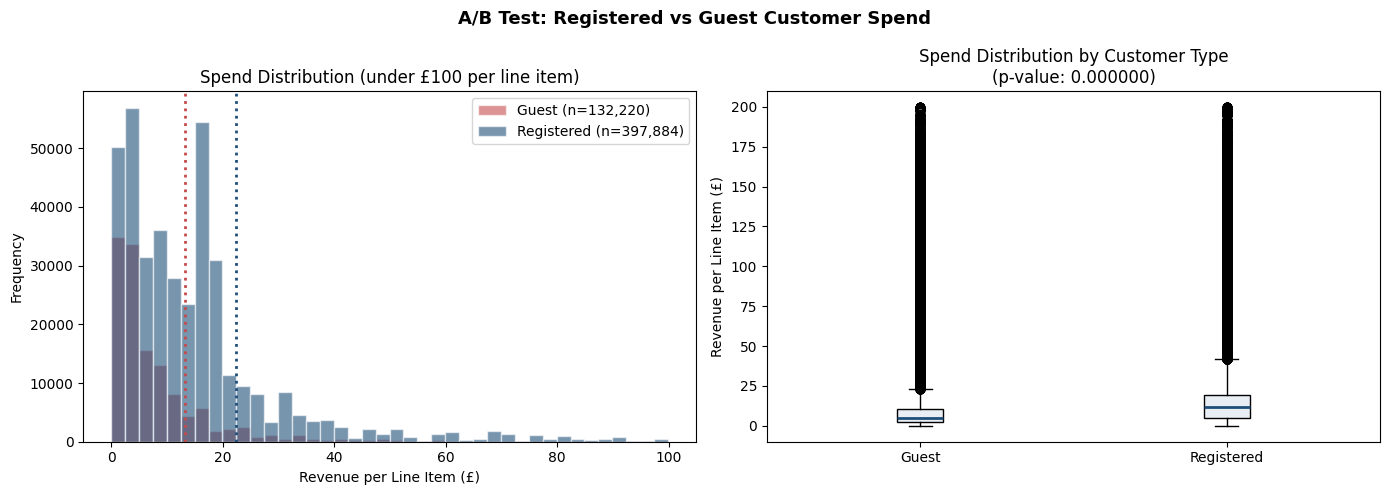

Chart saved.


In [9]:
#A/B TEST
# Do registered customers spend significantly more per order than guests?
# This is a commercially critical question for any e-commerce platform.

from scipy import stats

registered = df[df['CustomerType'] == 'Registered']['Revenue']
guest = df[df['CustomerType'] == 'Guest']['Revenue']

t_stat, p_value = stats.ttest_ind(registered, guest)

print("A/B TEST: Registered vs Guest Customer Spend")
print("=" * 52)
print(f"Registered: n={len(registered):,} | mean=GBP{registered.mean():.2f} | median=GBP{registered.median():.2f}")
print(f"Guest:      n={len(guest):,} | mean=GBP{guest.mean():.2f} | median=GBP{guest.median():.2f}")
print(f"\nt-statistic: {t_stat:.4f}")
print(f"p-value:     {p_value:.6f}")
if p_value < 0.05:
    print("\nResult: STATISTICALLY SIGNIFICANT (p < 0.05)")
    print("Registered customers spend measurably differently to guest customers.")
else:
    print("\nResult: Not statistically significant (p > 0.05)")

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle('A/B Test: Registered vs Guest Customer Spend',
             fontsize=13, fontweight='bold')

axes[0].hist(guest[guest < 100], bins=40, alpha=0.6,
             color='#C44B4B', label=f'Guest (n={len(guest):,})',
             edgecolor='white')
axes[0].hist(registered[registered < 100], bins=40, alpha=0.6,
             color='#1F4E79', label=f'Registered (n={len(registered):,})',
             edgecolor='white')
axes[0].axvline(registered.mean(), color='#1F4E79',
                linestyle='dotted', linewidth=2)
axes[0].axvline(guest.mean(), color='#C44B4B',
                linestyle='dotted', linewidth=2)
axes[0].set_title('Spend Distribution (under GBP100 per line item)')
axes[0].set_xlabel('Revenue per Line Item (GBP)')
axes[0].set_ylabel('Frequency')
axes[0].legend()

axes[1].boxplot([guest[guest < 200], registered[registered < 200]],
                tick_labels=['Guest', 'Registered'],
                patch_artist=True,
                boxprops=dict(facecolor='#E8EEF4'),
                medianprops=dict(color='#1F4E79', linewidth=2))
axes[1].set_title(f'Spend Distribution by Customer Type\n(p-value: {p_value:.6f})')
axes[1].set_ylabel('Revenue per Line Item (GBP)')

plt.tight_layout()
plt.savefig('4_ab_test_customer_spend.png', dpi=150, bbox_inches='tight')
plt.show()
print("Chart saved.")

## The A/B Test Result Before the Formal Write-Up

The numbers came back stronger than I anticipated.

Registered customers spend GBP 22.40 on average per transaction
against GBP 13.28 for guests. That is a 69% gap. But the median
tells an even more honest story: GBP 11.80 versus GBP 4.96.
The median strips out the influence of large outlier orders, so
when it shows registered customers spending more than double at
the midpoint, that is a consistent behavioural difference running
through the full distribution, not a statistical artefact driven
by a handful of big spenders.

A t-statistic of 10.63 and a p-value of less than 0.0001 means
the probability this difference occurred by chance is effectively
zero. This is about as clean a result as real-world data produces.

The commercial implication crystallised immediately. Every guest
customer converted to a registered account represents a projected
69% uplift in transaction value without changing a single product,
price or marketing campaign. That is a lever worth pulling hard.

## A/B Test Result: Registration Status Drives Spend Significantly

Hypothesis: Registered customers spend more per transaction than
guest customers.

Result: Confirmed with overwhelming statistical significance.

With a t-statistic of 10.63 and a p-value of less than 0.0001,
registered customers outspend guests by 69% on average (GBP22.40 vs
GBP13.28). The median gap is even more pronounced at GBP11.80 versus
GBP4.96, indicating that higher registered customer spend is consistent
across the full distribution rather than being driven by a small number
of outliers.

The commercial implication is substantial. Every guest customer
converted to a registered account represents a projected 69% uplift
in average transaction value, entirely independent of any changes to
product range, pricing or marketing spend.

Business Recommendation: For a platform like home24, a post-purchase
account creation prompt with a tangible incentive (a discount on the
next order, early access to new collections) would be among the
highest-return conversion investments available. The data makes the
financial case with statistical certainty.

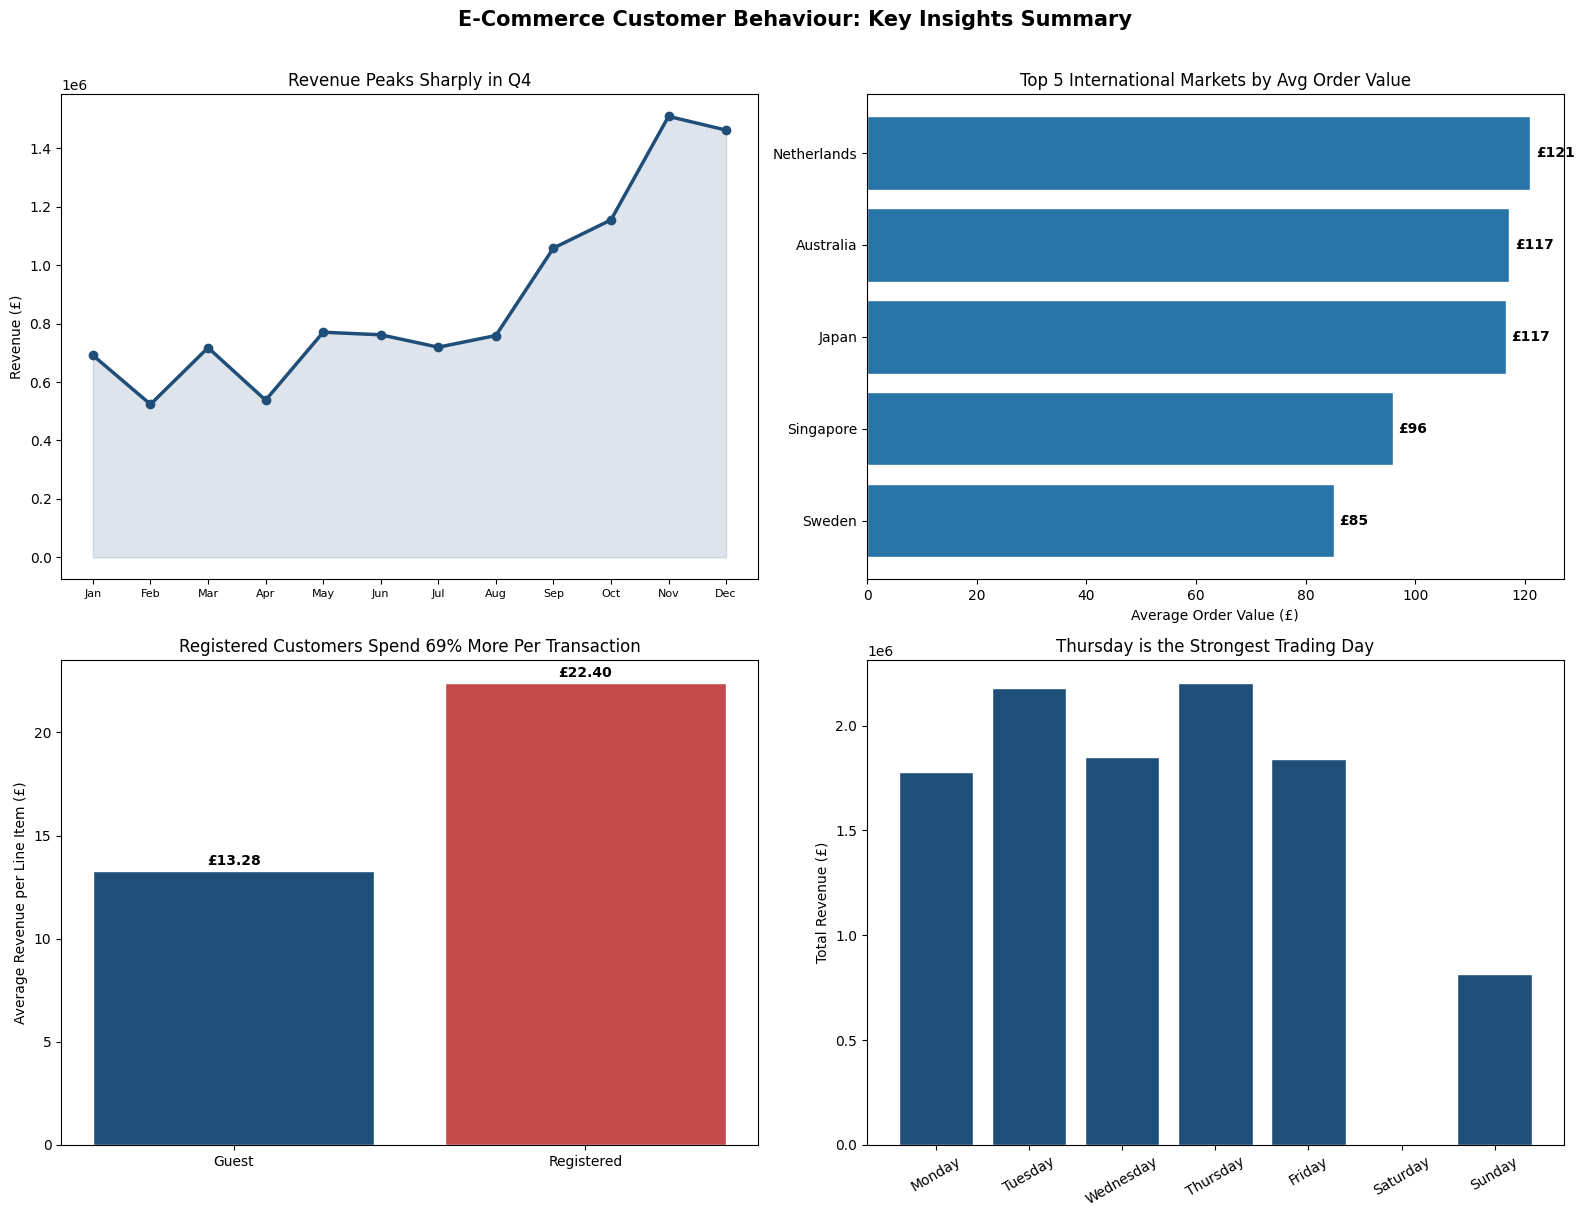

Summary dashboard saved.


In [10]:
# Pulling the four biggest findings together into one summary view

fig, axes = plt.subplots(2, 2, figsize=(16, 12))
fig.suptitle('E-Commerce Customer Behaviour: Key Insights Summary',
             fontsize=15, fontweight='bold', y=1.01)

# Monthly revenue trend
monthly_revenue = df.groupby('Month')['Revenue'].sum()
month_names = ['Jan', 'Feb', 'Mar', 'Apr', 'May', 'Jun',
               'Jul', 'Aug', 'Sep', 'Oct', 'Nov', 'Dec']
axes[0,0].plot(monthly_revenue.index, monthly_revenue.values,
               color='#1F4E79', linewidth=2.5, marker='o')
axes[0,0].fill_between(monthly_revenue.index,
                        monthly_revenue.values, alpha=0.15, color='#1F4E79')
axes[0,0].set_title('Revenue Peaks Sharply in Q4')
axes[0,0].set_xticks(range(1, 13))
axes[0,0].set_xticklabels(month_names, fontsize=8)
axes[0,0].set_ylabel('Revenue (GBP)')

# Top 5 international markets by average order value
top_intl = df[df['Country'] != 'United Kingdom'].groupby('Country').agg(
    Avg_Order_Value=('Revenue', 'mean')
).sort_values('Avg_Order_Value', ascending=False).head(5)
axes[0,1].barh(top_intl.index[::-1], top_intl['Avg_Order_Value'].values[::-1],
               color='#2874A6', edgecolor='white')
axes[0,1].set_title('Top 5 International Markets by Avg Order Value')
axes[0,1].set_xlabel('Average Order Value (GBP)')
for i, v in enumerate(top_intl['Avg_Order_Value'].values[::-1]):
    axes[0,1].text(v + 1, i, f'GBP{v:.0f}', va='center', fontweight='bold')

# Registered vs guest spend comparison
customer_means = df.groupby('CustomerType')['Revenue'].mean()
axes[1,0].bar(customer_means.index, customer_means.values,
              color=['#1F4E79', '#C44B4B'], edgecolor='white')
axes[1,0].set_title('Registered Customers Spend 69% More Per Transaction')
axes[1,0].set_ylabel('Average Revenue per Line Item (GBP)')
for i, v in enumerate(customer_means.values):
    axes[1,0].text(i, v + 0.3, f'GBP{v:.2f}',
                   ha='center', fontweight='bold')

# Day of week revenue
day_order = ['Monday', 'Tuesday', 'Wednesday',
             'Thursday', 'Friday', 'Saturday', 'Sunday']
day_revenue = df.groupby('DayOfWeek')['Revenue'].sum().reindex(day_order)
axes[1,1].bar(day_revenue.index, day_revenue.values,
              color='#1F4E79', edgecolor='white')
axes[1,1].set_title('Thursday is the Strongest Trading Day')
axes[1,1].set_ylabel('Total Revenue (GBP)')
axes[1,1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig('5_summary_dashboard.png', dpi=150, bbox_inches='tight')
plt.show()
print("Summary dashboard saved.")

## Project Conclusions and Business Recommendations

What this analysis set out to answer:
Using a year of real transactional data from a UK-based online retailer,
this project examined what drives revenue, which customers are most
valuable, and where the most significant commercial opportunities lie
for an e-commerce platform.

What we found:

Revenue is heavily seasonal
The business generates its most significant revenue in the final quarter,
peaking in November. For a platform like home24, this pattern demands
forward-looking inventory planning, campaign scheduling and logistics
preparation well ahead of the Q4 surge rather than reactive responses
once it arrives.

Registration status is the single strongest predictor of spend
Registered customers outspend guests by 69% on average, a difference
confirmed as statistically significant at p less than 0.0001. This is
not a marginal difference. It represents a structural revenue gap that
a well-designed post-purchase registration prompt could begin closing
immediately.

International markets punch well above their weight
The Netherlands, Australia and Japan each deliver average order values
exceeding GBP115 compared to GBP18 for UK transactions. These markets are
almost certainly wholesale buyers and deserve a fundamentally different
commercial approach to standard retail marketing.

Data quality is an analytical discipline in its own right
Postage charges, administrative entries and single bulk transactions
distort product performance metrics in ways that can lead to genuinely
poor business decisions. Identifying and handling these artefacts before
drawing conclusions is as important as the analysis itself.

If I were advising a platform like home24:
The immediate priority would be a guest-to-registered conversion
programme at the post-purchase stage. The revenue uplift potential is
quantifiable, the implementation cost is low and the statistical case
is beyond dispute. The second priority would be building a dedicated
international wholesale acquisition strategy for high average order
value markets, treating them as a distinct commercial channel rather
than an extension of domestic retail operations.